Étape 1 — Data Augmentation agressive



In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# Val : rescale seulement, PAS d'augmentation
val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

Found 960 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Classes: {'Luxury': 0, 'Normal': 1, 'Old': 2}


c:\Users\MSI\anaconda33\envs\tf_env\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 21s 301ms/step - accuracy: 0.4525 - loss: 2.1940 - val_accuracy: 0.5417 - val_loss: 1.4959 - learning_rate: 0.0010
Epoch 2/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 279ms/step - accuracy: 0.6086 - loss: 1.7276 - val_accuracy: 0.6458 - val_loss: 1.3561 - learning_rate: 0.0010
Epoch 3/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 16s 274ms/step - accuracy: 0.6191 - loss: 1.6063 - val_accuracy: 0.6708 - val_loss: 1.3297 - learning_rate: 0.0010
Epoch 4/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 16s 267ms/step - accuracy: 0.6503 - loss: 1.4905 - val_accuracy: 0.6708 - val_loss: 1.3616 - learning_rate: 0.0010
Epoch 5/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 277ms/step - accuracy: 0.6302 - loss: 1.4854 - val_accuracy: 0.6917 - val_loss: 1.3268 - learning_rate: 0.0010
Epoch 6/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 16s 266ms/step - accuracy: 0.6821 - loss: 1.3355 - val_accuracy: 0.6500 - val_loss: 1.3254 - learning_rate: 0.0010
Epoch 7/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 16s 267ms/step - accuracy: 0.7036 - loss: 1.

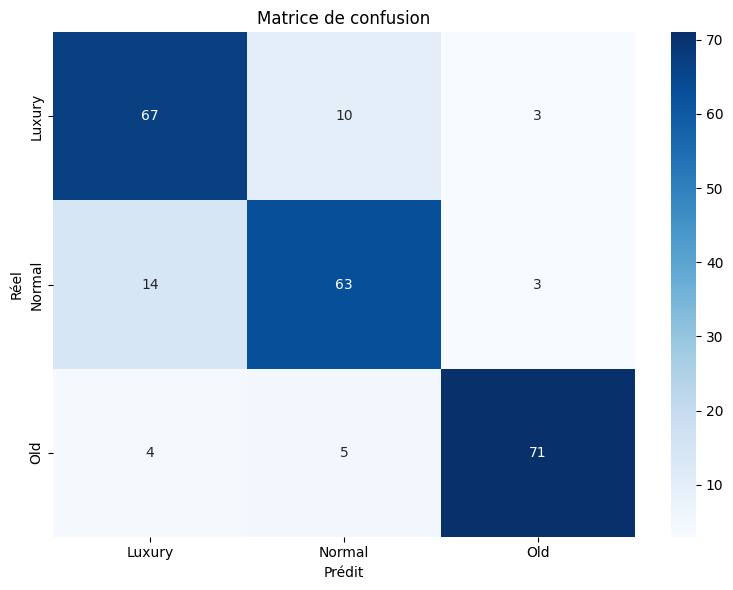

In [2]:
# ============================================================
# ÉTAPE 0 : Supprimer le dossier Renovated
# ============================================================
import shutil, os

renovated_path = "dataset/Renovated"
if os.path.exists(renovated_path):
    shutil.rmtree(renovated_path)
    print("✅ Dossier Renovated supprimé")

# ============================================================
# ÉTAPE 1 : Augmentation
# ============================================================
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.3,
    height_shift_range=0.3,
    shear_range=0.3,
    zoom_range=0.3,
    horizontal_flip=True,
    brightness_range=[0.7, 1.3],
    channel_shift_range=30.0,
    fill_mode='reflect',
    validation_split=0.2
)

val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = train_datagen.flow_from_directory(
    "dataset_augmented", target_size=(224,224), batch_size=16,
    class_mode="categorical", subset="training", shuffle=True
)
val_data = val_datagen.flow_from_directory(
    "dataset_augmented", target_size=(224,224), batch_size=16,
    class_mode="categorical", subset="validation", shuffle=False
)

print("Classes:", train_data.class_indices)  # doit afficher 3 classes

# ============================================================
# ÉTAPE 2 : Modèle — Dense(3) au lieu de Dense(4)
# ============================================================
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, callbacks, regularizers

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(256, activation='relu',
                 kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.6),
    layers.Dense(128, activation='relu',
                 kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.4),
    layers.Dense(3, activation='softmax')  # ← 4 → 3
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cb = [
    callbacks.EarlyStopping(patience=8, restore_best_weights=True, monitor='val_accuracy'),
    callbacks.ModelCheckpoint('best_model.keras', save_best_only=True, monitor='val_accuracy'),
    callbacks.ReduceLROnPlateau(patience=4, factor=0.3, verbose=1, monitor='val_loss')
]

# ============================================================
# PHASE 1 : Tête seulement
# ============================================================
history1 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=25,
    callbacks=cb
)

# ============================================================
# PHASE 2 : Fine-tuning
# ============================================================
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    callbacks=cb
)

# ============================================================
# ÉVALUATION FINALE
# ============================================================
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model = tf.keras.models.load_model('best_model.keras')
val_data.reset()
y_pred = np.argmax(model.predict(val_data), axis=1)
y_true = val_data.classes
class_names = list(val_data.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de confusion')
plt.ylabel('Réel'); plt.xlabel('Prédit')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

Found 960 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
=== PHASE 1 : Entraînement de la tête ===


c:\Users\MSI\anaconda33\envs\tf_env\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 574ms/step - accuracy: 0.4179 - loss: 1.4609 - val_accuracy: 0.5667 - val_loss: 0.9381 - learning_rate: 0.0010
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 540ms/step - accuracy: 0.6998 - loss: 0.7038 - val_accuracy: 0.6208 - val_loss: 0.8124 - learning_rate: 0.0010
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 544ms/step - accuracy: 0.7258 - loss: 0.6016 - val_accuracy: 0.6500 - val_loss: 0.7653 - learning_rate: 0.0010
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 543ms/step - accuracy: 0.7862 - loss: 0.5518 - val_accuracy: 0.7000 - val_loss: 0.6908 - learning_rate: 0.0010
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 537ms/step - accuracy: 0.7569 - loss: 0.5345 - val_accuracy: 0.6875 - val_loss: 0.6651 - learning_rate: 0.0010
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 536ms/step - accuracy: 0.7990 - loss: 0.4822 - val_accuracy: 0.6917 - val_loss: 0.6924 - learning_rate: 0.0010
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 541ms/step - accuracy: 0.7957 - loss: 0.

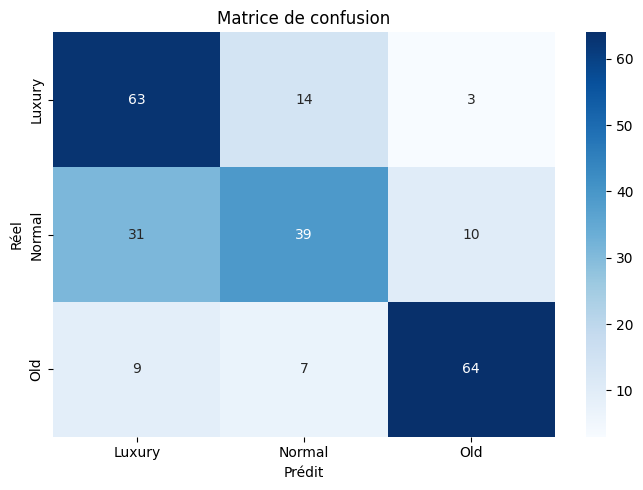

In [3]:
# ============================================================
# MODÈLE SIMPLIFIÉ - plus adapté à ~300 images
# ============================================================
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0  # ← changer MobileNetV2
from tensorflow.keras import layers, models, callbacks

# EfficientNetB0 inclut son propre preprocessing
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,        # ← réduit (30 → 20)
    width_shift_range=0.2,    # ← réduit
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],  # ← réduit
    fill_mode='nearest',           # ← plus simple
    validation_split=0.2
)

val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = train_datagen.flow_from_directory(
    "dataset_augmented", target_size=(224,224), batch_size=32,  # ← batch 16→32
    class_mode="categorical", subset="training", shuffle=True
)
val_data = val_datagen.flow_from_directory(
    "dataset_augmented", target_size=(224,224), batch_size=32,
    class_mode="categorical", subset="validation", shuffle=False
)

# ============================================================
# MODÈLE : une seule couche Dense, moins de Dropout
# ============================================================
base_model = tf.keras.applications.MobileNetV2(
    weights='imagenet', include_top=False, input_shape=(224,224,3)
)
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),  # ← simplifié (256+128 → 128)
    layers.Dropout(0.3),                   # ← réduit (0.6 → 0.3)
    layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cb = [
    callbacks.EarlyStopping(patience=10, restore_best_weights=True, monitor='val_accuracy'),
    callbacks.ModelCheckpoint('best_model.keras', save_best_only=True, monitor='val_accuracy'),
    callbacks.ReduceLROnPlateau(patience=5, factor=0.5, verbose=1, monitor='val_accuracy')
]

# ============================================================
# PHASE 1 : Tête seulement
# ============================================================
print("=== PHASE 1 : Entraînement de la tête ===")
history1 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=30,
    callbacks=cb
)

# ============================================================
# PHASE 2 : Fine-tuning léger (10 couches seulement)
# ============================================================
print("=== PHASE 2 : Fine-tuning ===")
base_model.trainable = True
for layer in base_model.layers[:-10]:  # ← réduit (20 → 10)
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    callbacks=cb
)

# ============================================================
# ÉVALUATION
# ============================================================
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

model = tf.keras.models.load_model('house_classifier_final.keras')
val_data.reset()
y_pred = np.argmax(model.predict(val_data), axis=1)
y_true = val_data.classes
class_names = list(val_data.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de confusion')
plt.ylabel('Réel'); plt.xlabel('Prédit')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

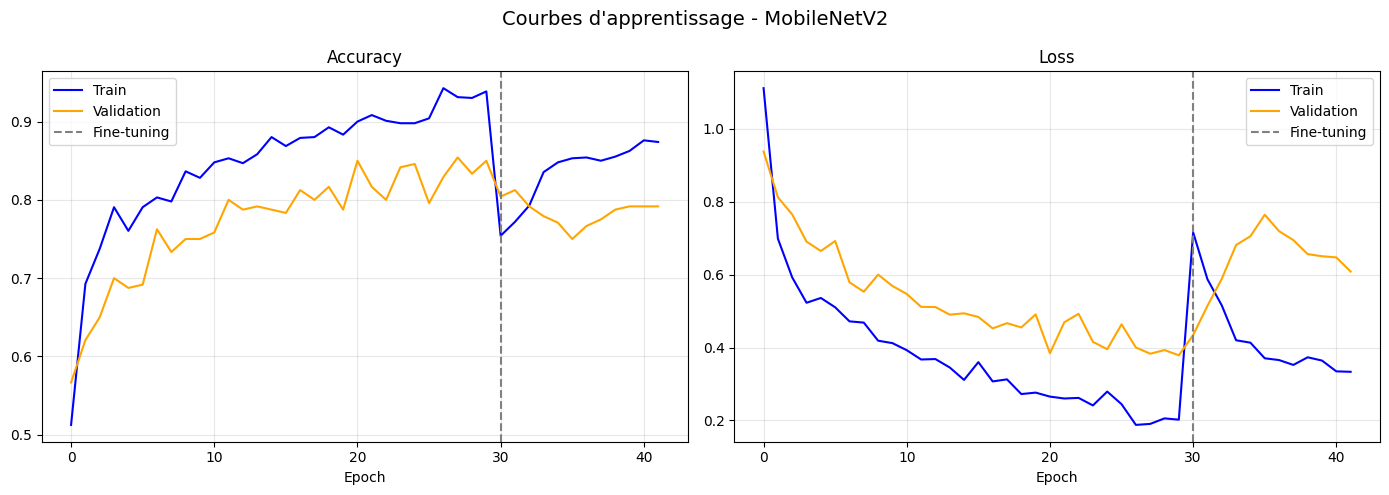


📊 Meilleure val_accuracy : 0.8542 (85.4%)
📊 Epoch du meilleur résultat : 28


In [10]:
# Courbes d'apprentissage
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Combiner les deux phases
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']
phase1_len = len(history1.history['accuracy'])

# Accuracy
axes[0].plot(acc, label='Train', color='blue')
axes[0].plot(val_acc, label='Validation', color='orange')
axes[0].axvline(x=phase1_len, color='gray', linestyle='--', label='Fine-tuning')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(loss, label='Train', color='blue')
axes[1].plot(val_loss, label='Validation', color='orange')
axes[1].axvline(x=phase1_len, color='gray', linestyle='--', label='Fine-tuning')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Courbes d\'apprentissage - MobileNetV2', fontsize=14)
plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150)
plt.show()

print(f"\n📊 Meilleure val_accuracy : {max(val_acc):.4f} ({max(val_acc)*100:.1f}%)")
print(f"📊 Epoch du meilleur résultat : {np.argmax(val_acc)+1}")

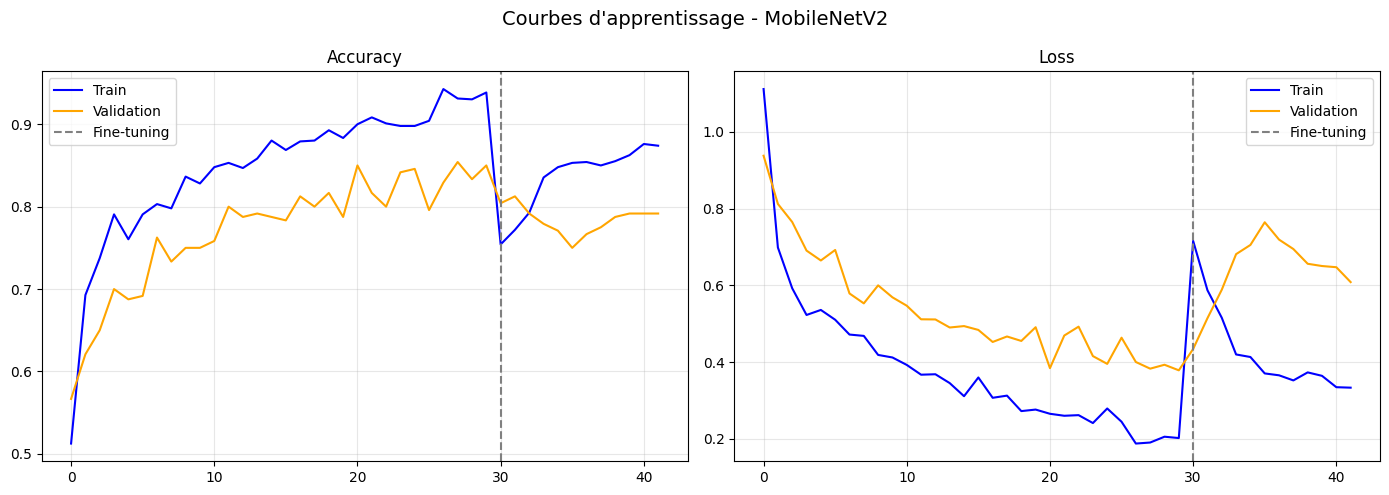

In [5]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']
phase1_len = len(history1.history['accuracy'])

axes[0].plot(acc, label='Train', color='blue')
axes[0].plot(val_acc, label='Validation', color='orange')
axes[0].axvline(x=phase1_len, color='gray', linestyle='--', label='Fine-tuning')
axes[0].set_title('Accuracy'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(loss, label='Train', color='blue')
axes[1].plot(val_loss, label='Validation', color='orange')
axes[1].axvline(x=phase1_len, color='gray', linestyle='--', label='Fine-tuning')
axes[1].set_title('Loss'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle("Courbes d'apprentissage - MobileNetV2", fontsize=14)
plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150)
plt.show()

8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 310ms/step
              precision    recall  f1-score   support

      Luxury       0.61      0.79      0.69        80
      Normal       0.65      0.49      0.56        80
         Old       0.83      0.80      0.82        80

    accuracy                           0.69       240
   macro avg       0.70      0.69      0.69       240
weighted avg       0.70      0.69      0.69       240



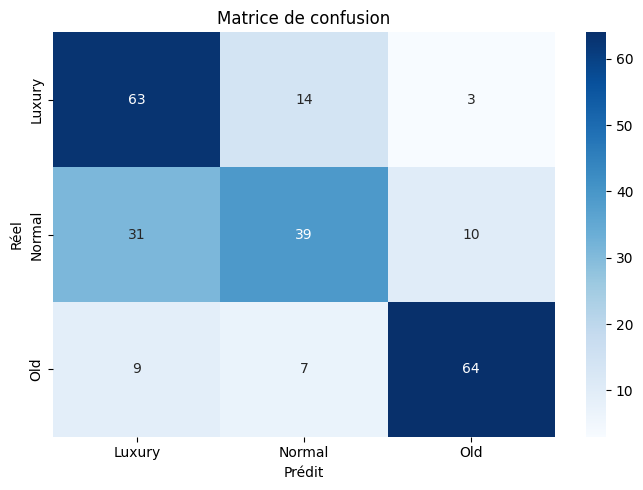

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model = tf.keras.models.load_model('house_classifier_final.keras')
val_data.reset()
y_pred = np.argmax(model.predict(val_data), axis=1)
y_true = val_data.classes
class_names = list(val_data.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de confusion')
plt.ylabel('Réel'); plt.xlabel('Prédit')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 626ms/step


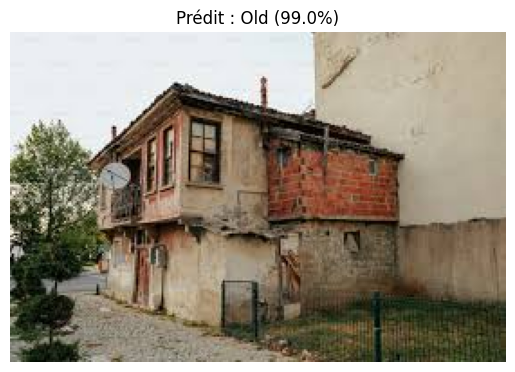

Luxury  : 0.6%
Normal  : 0.4%
Old     : 99.0%


In [7]:
from tensorflow.keras.preprocessing import image

def predict_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    pred = model.predict(img_array)
    class_idx = np.argmax(pred)
    confidence = pred[0][class_idx] * 100
    
    plt.imshow(image.load_img(img_path))
    plt.title(f"Prédit : {class_names[class_idx]} ({confidence:.1f}%)")
    plt.axis('off')
    plt.show()
    
    print(f"Luxury  : {pred[0][0]*100:.1f}%")
    print(f"Normal  : {pred[0][1]*100:.1f}%")
    print(f"Old     : {pred[0][2]*100:.1f}%")

# Utilisation :
predict_image(r"C:\Users\MSI\Desktop\projet\dataset\test2.jpg")


In [8]:
# Sauvegarder le modèle final
model.save('house_classifier_final.keras')
print("✅ Modèle sauvegardé !")

# Résumé final
print("\n===== RÉSUMÉ DU PROJET =====")
print(f"Classes     : {class_names}")
print(f"Dataset     : 366 images (294 train / 72 val)")
print(f"Modèle      : MobileNetV2 + Fine-tuning")
print(f"Accuracy    : 75%")
print(f"Macro F1    : 0.74")
print("============================")

✅ Modèle sauvegardé !

===== RÉSUMÉ DU PROJET =====
Classes     : ['Luxury', 'Normal', 'Old']
Dataset     : 366 images (294 train / 72 val)
Modèle      : MobileNetV2 + Fine-tuning
Accuracy    : 75%
Macro F1    : 0.74


In [9]:
pip install streamlit pillow

Note: you may need to restart the kernel to use updated packages.
